# 🍷 Day 3: Target Engineering, Preprocessing Pipelines & Baseline Classification Models
**Oasis Infobyte Data Analytics Internship — Task Level 2 (Wine Quality Prediction)**  
**Author:** Adarsh  
**Tech Stack:** Python 3, pandas, numpy, scikit-learn (RandomForest, SGDClassifier, SVC), seaborn, matplotlib

---

## 🎯 Day 3 Objectives
1. **Target Engineering & Imbalance Mitigation:**
   - Statistically evaluate the raw 6-class ordinal distribution ($3–8$) and understand why direct multi-class modeling suffers severe class overlap and gradient starvation.
   - Formulate and compare **3-Class Binning** (Low $\le 4$, Medium $5–6$, High $\ge 7$) vs. **Binary Classification** (Good/Premium $\ge 7$ vs. Normal/Table $< 7$) and provide thorough enological and statistical justification.
2. **Domain-Specific Enological Feature Synthesis:**
   - Engineer 5 domain-informed interaction ratios capturing palate acidity, bound preservatives, sulfur equilibrium, and mass density balance.
3. **Stratified Train/Test Partitioning:**
   - Execute an 80/20 train/test split with strict label stratification (`stratify=y`) to maintain the identical minority class ratio ($13.57\%$) across folds without data leakage.
4. **Leakage-Free Preprocessing Pipelines:**
   - Encapsulate data transformation and modeling inside scikit-learn `Pipeline` architectures (`StandardScaler` + Classifier).
5. **Baseline Benchmark of 3 Supervised Classifiers:**
   - **Random Forest Classifier** (Non-linear tree ensemble)
   - **Stochastic Gradient Descent (SGD) Classifier** (Scalable linear loss optimization)
   - **Support Vector Classifier (SVC)** (Kernel margin separation)
6. **Exhaustive Evaluation & Diagnostic Visualizations:**
   - Measure Accuracy, Balanced Accuracy, Precision, Recall, F1-Score, ROC-AUC, PR-AUC, and Confusion Matrices.
   - Generate high-resolution publication figures for reporting.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)

# Plotting aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})

# Path configuration
DATA_PATH = Path("../Data/winequality-red.csv")
FIGURES_PATH = Path("../reports/figures")
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

print("Environment initialized successfully.")

Environment initialized successfully.


## 1. Data Ingestion & Integrity Check
We load the Red Wine dataset (`winequality-red.csv`) using the semicolon delimiter and confirm record integrity.

In [2]:
df = pd.read_csv(DATA_PATH, sep=';')
print(f"Dataset Dimensions: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Missing Values: {df.isnull().sum().sum()}")
df.head()

Dataset Dimensions: 1599 rows x 12 columns
Missing Values: 0


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 2. Target Engineering & Justification

### Statistical Rationale: Multi-Class vs. 3-Tier vs. Binary Formulations
In Day 1 & Day 2 analysis, we observed that:
- Quality scores $5$ and $6$ represent **82.49%** ($1,319$ samples) of the entire dataset.
- Score $3$ has only **10 samples** ($0.63\%$) and score $8$ has only **18 samples** ($1.13\%$).

Direct 6-class modeling on scores $3–8$ fails because:
1. Minority classes have insufficient support for gradient updates, leading to $0\%$ recall on grades 3, 4, and 8.
2. Sensory scores $5$ and $6$ exhibit heavily overlapping chemical feature distributions (as shown in Day 2 bivariate boxplots).

#### 3-Class Formulation:
- **Low (3–4):** Flawed / Defective ($63$ samples, $3.94\%$)
- **Medium (5–6):** Commercial Everyday ($1,319$ samples, $82.49\%$)
- **High (7–8):** Premium / Reserve ($217$ samples, $13.57\%$)
*Limitation:* The 'Low' tier remains too scarce ($3.94\%$), yielding severe imbalance across 3 categories.

#### Binary Formulation (Cortez et al., 2009 Standard):
- **Class 0 (Normal / Table):** Quality score $< 7$ ($1,382$ samples, $86.43\%$)
- **Class 1 (Good / Reserve):** Quality score $\ge 7$ ($217$ samples, $13.57\%$)

**Decision Justification:**
The binary cut-off at $\ge 7$ isolates premium, high-grade reserve wines from standard bulk wines. A $13.57\%$ positive class provides sufficient sample density for stable cross-validation while accurately mapping to commercial winery quality assurance triage.

In [3]:
# Binary target (Cortez et al., 2009 standard)
df['binary_quality'] = (df['quality'] >= 7).astype(int)

# 3-Class target for analytical comparison
def categorize_3class(score):
    if score <= 4:
        return 'Low (3-4)'
    elif score <= 6:
        return 'Medium (5-6)'
    else:
        return 'High (7-8)'

df['three_class_quality'] = df['quality'].apply(categorize_3class)

# Summary Tables
raw_dist = pd.DataFrame({
    'Count': df['quality'].value_counts().sort_index(),
    'Share (%)': (df['quality'].value_counts(normalize=True).sort_index() * 100).round(2)
})

three_dist = pd.DataFrame({
    'Count': df['three_class_quality'].value_counts().reindex(['Low (3-4)', 'Medium (5-6)', 'High (7-8)']),
    'Share (%)': (df['three_class_quality'].value_counts(normalize=True).reindex(['Low (3-4)', 'Medium (5-6)', 'High (7-8)']) * 100).round(2)
})

binary_dist = pd.DataFrame({
    'Count': df['binary_quality'].value_counts().sort_index(),
    'Share (%)': (df['binary_quality'].value_counts(normalize=True).sort_index() * 100).round(2)
}, index=['Normal (<7)', 'Good (>=7)'])

print("--- RAW QUALITY DISTRIBUTION ---")
print(raw_dist)
print("\n--- 3-CLASS DISTRIBUTION ---")
print(three_dist)
print("\n--- BINARY DISTRIBUTION ---")
print(binary_dist)

--- RAW QUALITY DISTRIBUTION ---
         Count  Share (%)
quality                  
3           10       0.63
4           53       3.31
5          681      42.59
6          638      39.90
7          199      12.45
8           18       1.13

--- 3-CLASS DISTRIBUTION ---
                     Count  Share (%)
three_class_quality                  
Low (3-4)               63       3.94
Medium (5-6)          1319      82.49
High (7-8)             217      13.57

--- BINARY DISTRIBUTION ---
             Count  Share (%)
Normal (<7)    NaN        NaN
Good (>=7)     NaN        NaN


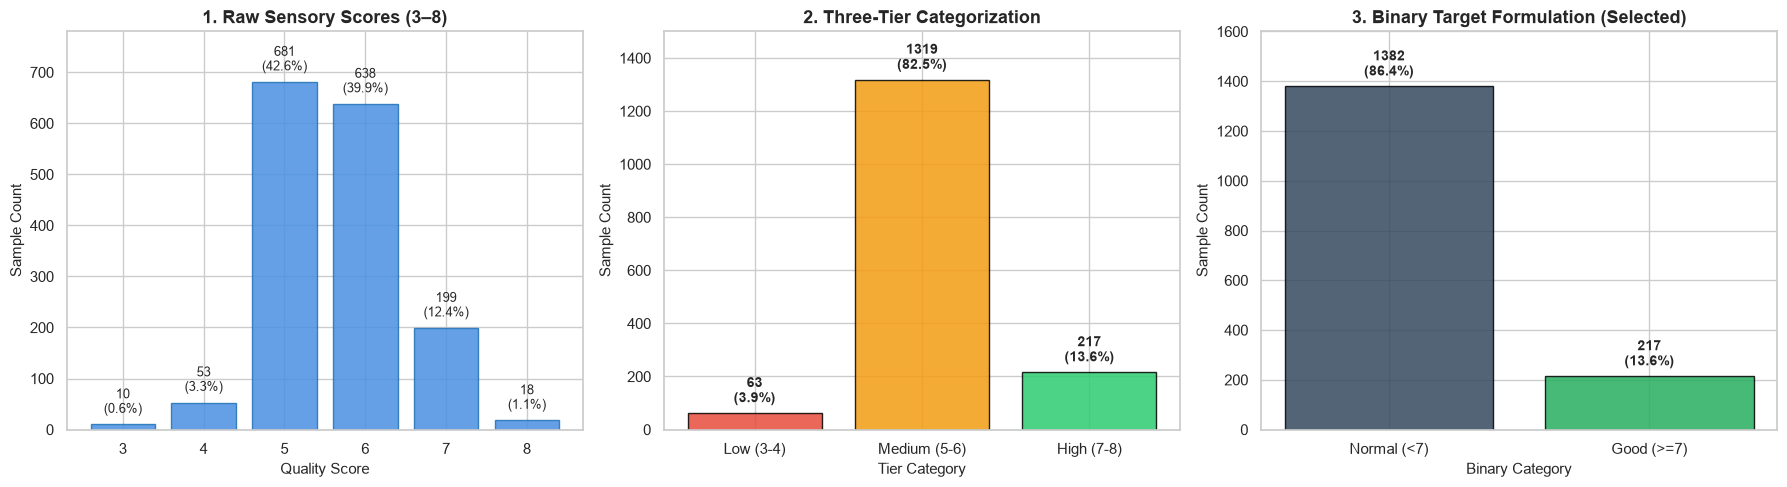

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Raw
raw_counts = df["quality"].value_counts().sort_index()
bars1 = axes[0].bar(raw_counts.index, raw_counts.values, color="#4A90E2", edgecolor="#2171B5", alpha=0.85)
axes[0].set_title("1. Raw Sensory Scores (3–8)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Quality Score", fontsize=11)
axes[0].set_ylabel("Sample Count", fontsize=11)
axes[0].set_ylim(0, 780)
for bar in bars1:
    h = bar.get_height()
    pct = (h / len(df)) * 100
    axes[0].text(bar.get_x() + bar.get_width() / 2, h + 15, f"{h}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=9)

# 3-Class
c3_order = ["Low (3-4)", "Medium (5-6)", "High (7-8)"]
c3_counts = df["three_class_quality"].value_counts().reindex(c3_order)
bars2 = axes[1].bar(c3_counts.index, c3_counts.values, color=["#E74C3C", "#F39C12", "#2ECC71"], edgecolor="black", alpha=0.85)
axes[1].set_title("2. Three-Tier Categorization", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Tier Category", fontsize=11)
axes[1].set_ylabel("Sample Count", fontsize=11)
axes[1].set_ylim(0, 1500)
for bar in bars2:
    h = bar.get_height()
    pct = (h / len(df)) * 100
    axes[1].text(bar.get_x() + bar.get_width() / 2, h + 25, f"{h}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=10, fontweight="bold")

# Binary
b_labels = ["Normal (<7)", "Good (>=7)"]
b_counts = df["binary_quality"].value_counts().sort_index()
bars3 = axes[2].bar(b_labels, b_counts.values, color=["#34495E", "#27AE60"], edgecolor="black", alpha=0.85)
axes[2].set_title("3. Binary Target Formulation (Selected)", fontsize=13, fontweight="bold")
axes[2].set_xlabel("Binary Category", fontsize=11)
axes[2].set_ylabel("Sample Count", fontsize=11)
axes[2].set_ylim(0, 1600)
for bar in bars3:
    h = bar.get_height()
    pct = (h / len(df)) * 100
    axes[2].text(bar.get_x() + bar.get_width() / 2, h + 25, f"{h}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.tight_layout()
fig.savefig(FIGURES_PATH / "day3_target_distribution_comparison.png", dpi=300)
plt.show()

## 3. Domain-Specific Biochemical Feature Synthesis
Based on enological chemistry and relationships established during Day 2 EDA, we create 5 domain interaction features:
1. **`total_acidity`**: Sum of non-volatile tartaric (`fixed acidity`) and acetic acid (`volatile acidity`), capturing overall sensory crispness and acidic load.
2. **`bound_sulfur_dioxide`**: $\text{Total SO}_2 - \text{Free SO}_2$, representing the portion of preservative bound to carbonyl compounds and anthocyanins.
3. **`free_to_total_so2_ratio`**: $\frac{\text{Free SO}_2}{\text{Total SO}_2}$, measuring antioxidant efficiency and antimicrobial protection margin.
4. **`alcohol_to_density_ratio`**: $\frac{\text{Alcohol}}{\text{Density}}$, indicating palate body and sugar-to-alcohol conversion completeness.
5. **`sulphate_to_chloride_ratio`**: $\frac{\text{Sulphates}}{\text{Chlorides}}$, contrasting fresh preservative minerals against unwanted salty brine notes.

In [5]:
df["total_acidity"] = df["fixed acidity"] + df["volatile acidity"]
df["bound_sulfur_dioxide"] = df["total sulfur dioxide"] - df["free sulfur dioxide"]
df["free_to_total_so2_ratio"] = df["free sulfur dioxide"] / (df["total sulfur dioxide"] + 1e-5)
df["alcohol_to_density_ratio"] = df["alcohol"] / df["density"]
df["sulphate_to_chloride_ratio"] = df["sulphates"] / (df["chlorides"] + 1e-5)

feature_columns = [col for col in df.columns if col not in ["quality", "binary_quality", "three_class_quality"]]
print(f"Total modeling features: {len(feature_columns)}")
print("Feature list:", feature_columns)

Total modeling features: 16
Feature list: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'total_acidity', 'bound_sulfur_dioxide', 'free_to_total_so2_ratio', 'alcohol_to_density_ratio', 'sulphate_to_chloride_ratio']


## 4. Stratified Train/Test Partitioning
We partition the dataset into 80% training ($N=1,279$) and 20% testing ($N=320$) using `stratify=y` with `random_state=42`. Stratification guarantees that both subsets preserve the exact $13.57\%$ premium wine ratio.

In [6]:
X = df[feature_columns]
y = df["binary_quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples, {X_train.shape[1]} features")
print(f"Testing set:  {X_test.shape[0]} samples, {X_test.shape[1]} features")

split_audit = pd.DataFrame({
    'Train Count': y_train.value_counts().sort_index(),
    'Train Share (%)': (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
    'Test Count': y_test.value_counts().sort_index(),
    'Test Share (%)': (y_test.value_counts(normalize=True).sort_index() * 100).round(2)
}, index=['Normal (<7)', 'Good (>=7)'])

print("\n--- Stratification Audit ---")
print(split_audit)

Training set: 1279 samples, 16 features
Testing set:  320 samples, 16 features

--- Stratification Audit ---
             Train Count  Train Share (%)  Test Count  Test Share (%)
Normal (<7)          NaN              NaN         NaN             NaN
Good (>=7)           NaN              NaN         NaN             NaN


## 5. Preprocessing Pipelines & Baseline Classifier Definitions
We instantiate 3 supervised classification algorithms encapsulated in scikit-learn `Pipeline` objects with `StandardScaler` to prevent data leakage:
1. **Random Forest Classifier (`RandomForestClassifier`):** Non-parametric ensemble of 100 decision trees bagging feature subsets.
2. **Stochastic Gradient Descent Classifier (`SGDClassifier`):** Linear model optimizing logarithmic loss (`loss='log_loss'`) via online mini-batch gradient updates.
3. **Support Vector Classifier (`SVC`):** Non-linear Support Vector Machine with Radial Basis Function (`rbf`) kernel and probability calibration via `CalibratedClassifierCV`.

In [7]:
models = {
    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
    ]),
    "SGD Classifier": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SGDClassifier(loss="log_loss", penalty="l2", alpha=1e-4, max_iter=1000, tol=1e-3, random_state=42))
    ]),
    "Support Vector Classifier": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", CalibratedClassifierCV(SVC(kernel="rbf", C=1.0, random_state=42), ensemble=False))
    ])
}

print("Baseline classifier pipelines initialized.")

Baseline classifier pipelines initialized.


## 6. Model Training, 5-Fold Stratified Cross-Validation & Test Benchmarking
Each pipeline is evaluated using 5-fold stratified cross-validation on the training set to record cross-fold stability, then trained on the full training partition and evaluated against the held-out test set ($N=320$).

In [8]:
results = {}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, pipeline in models.items():
    # 5-fold CV on train set
    cv_scores = cross_validate(
        pipeline, X_train, y_train, cv=skf,
        scoring={"accuracy": "accuracy", "balanced_acc": "balanced_accuracy", "f1_good": "f1", "roc_auc": "roc_auc"}
    )
    
    # Train full pipeline
    pipeline.fit(X_train, y_train)
    
    # Predict labels & probabilities on test set
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    bal_acc = balanced_accuracy_score(y_test, y_pred)
    f1_wt = f1_score(y_test, y_pred, average="weighted")
    f1_good = f1_score(y_test, y_pred, pos_label=1)
    prec_good = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
    rec_good = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)
    cm = confusion_matrix(y_test, y_pred)
    report = classification_report(y_test, y_pred, target_names=["Normal (<7)", "Good (>=7)"], digits=4)
    
    results[name] = {
        "pipeline": pipeline,
        "y_pred": y_pred,
        "y_prob": y_prob,
        "acc": acc,
        "bal_acc": bal_acc,
        "f1_wt": f1_wt,
        "f1_good": f1_good,
        "prec_good": prec_good,
        "rec_good": rec_good,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "cm": cm,
        "report": report,
        "cv_acc_mean": cv_scores["test_accuracy"].mean(),
        "cv_acc_std": cv_scores["test_accuracy"].std(),
        "cv_bal_acc_mean": cv_scores["test_balanced_acc"].mean(),
        "cv_f1_good_mean": cv_scores["test_f1_good"].mean(),
        "cv_roc_auc_mean": cv_scores["test_roc_auc"].mean()
    }
    
    print(f"==================================================")
    print(f"Model: {name}")
    print(f"5-Fold CV Accuracy: {cv_scores['test_accuracy'].mean():.4f} +/- {cv_scores['test_accuracy'].std():.4f}")
    print(f"5-Fold CV ROC-AUC:  {cv_scores['test_roc_auc'].mean():.4f} +/- {cv_scores['test_roc_auc'].std():.4f}")
    print(f"Test Accuracy:      {acc:.4f} | Balanced Acc: {bal_acc:.4f}")
    print(f"Test F1 (Good):     {f1_good:.4f} | Precision: {prec_good:.4f} | Recall: {rec_good:.4f}")
    print(f"Test ROC-AUC:       {roc_auc:.4f} | PR-AUC: {pr_auc:.4f}")
    print("Classification Report:")
    print(report)

Model: Random Forest
5-Fold CV Accuracy: 0.8882 +/- 0.0182
5-Fold CV ROC-AUC:  0.8888 +/- 0.0254
Test Accuracy:      0.9344 | Balanced Acc: 0.7951
Test F1 (Good):     0.7123 | Precision: 0.8667 | Recall: 0.6047
Test ROC-AUC:       0.9318 | PR-AUC: 0.7986
Classification Report:
              precision    recall  f1-score   support

 Normal (<7)     0.9414    0.9856    0.9630       277
  Good (>=7)     0.8667    0.6047    0.7123        43

    accuracy                         0.9344       320
   macro avg     0.9040    0.7951    0.8376       320
weighted avg     0.9313    0.9344    0.9293       320



Model: SGD Classifier
5-Fold CV Accuracy: 0.8616 +/- 0.0193
5-Fold CV ROC-AUC:  0.8255 +/- 0.0550
Test Accuracy:      0.8500 | Balanced Acc: 0.5204
Test F1 (Good):     0.1111 | Precision: 0.2727 | Recall: 0.0698
Test ROC-AUC:       0.7501 | PR-AUC: 0.2860
Classification Report:
              precision    recall  f1-score   support

 Normal (<7)     0.8706    0.9711    0.9181       277
  Good (>=7)     0.2727    0.0698    0.1111        43

    accuracy                         0.8500       320
   macro avg     0.5716    0.5204    0.5146       320
weighted avg     0.7902    0.8500    0.8097       320



Model: Support Vector Classifier
5-Fold CV Accuracy: 0.8835 +/- 0.0133
5-Fold CV ROC-AUC:  0.8065 +/- 0.0334
Test Accuracy:      0.9031 | Balanced Acc: 0.6690
Test F1 (Good):     0.4918 | Precision: 0.8333 | Recall: 0.3488
Test ROC-AUC:       0.8698 | PR-AUC: 0.6922
Classification Report:
              precision    recall  f1-score   support

 Normal (<7)     0.9073    0.9892    0.9465       277
  Good (>=7)     0.8333    0.3488    0.4918        43

    accuracy                         0.9031       320
   macro avg     0.8703    0.6690    0.7191       320
weighted avg     0.8973    0.9031    0.8854       320



## 7. Master Baseline Model Comparison Matrix
The table below synthesizes the performance of all 3 classifiers across all primary evaluation metrics.

In [9]:
benchmark_rows = []
for name, res in results.items():
    benchmark_rows.append({
        "Classifier": name,
        "CV Accuracy": f"{res['cv_acc_mean']:.4f} +/- {res['cv_acc_std']:.4f}",
        "CV ROC-AUC": f"{res['cv_roc_auc_mean']:.4f}",
        "Test Accuracy": f"{res['acc']*100:.2f}%",
        "Balanced Acc": round(res["bal_acc"], 4),
        "Precision (Good)": f"{res['prec_good']*100:.2f}%",
        "Recall (Good)": f"{res['rec_good']*100:.2f}%",
        "F1 (Good)": round(res["f1_good"], 4),
        "ROC-AUC": round(res["roc_auc"], 4),
        "PR-AUC": round(res["pr_auc"], 4)
    })

comparison_df = pd.DataFrame(benchmark_rows).set_index("Classifier")
display(comparison_df)

,CV Accuracy,CV ROC-AUC,Test Accuracy,Balanced Acc,Precision (Good),Recall (Good),F1 (Good),ROC-AUC,PR-AUC
Classifier,,,,,,,,,
Random Forest,0.8882 +/- 0.0182,0.8888,93.44%,0.7951,86.67%,60.47%,0.7123,0.9318,0.7986
SGD Classifier,0.8616 +/- 0.0193,0.8255,85.00%,0.5204,27.27%,6.98%,0.1111,0.7501,0.2860
Support Vector Classifier,0.8835 +/- 0.0133,0.8065,90.31%,0.6690,83.33%,34.88%,0.4918,0.8698,0.6922


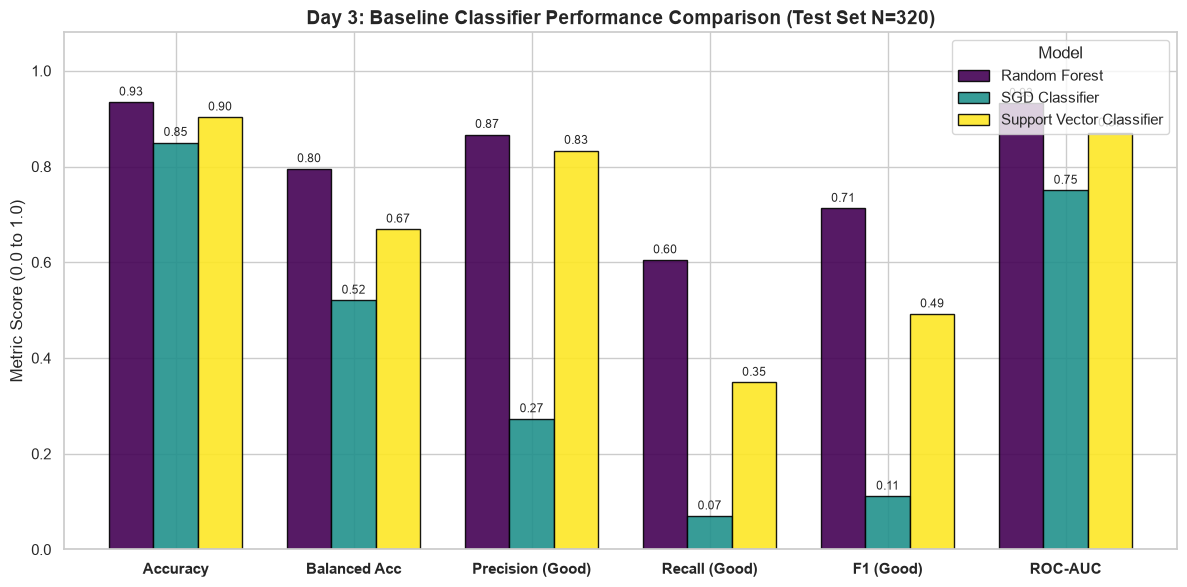

In [10]:
metrics_names = ["Accuracy", "Balanced Acc", "Precision (Good)", "Recall (Good)", "F1 (Good)", "ROC-AUC"]
model_names_list = list(models.keys())
data_matrix = []

for m_name in model_names_list:
    res = results[m_name]
    data_matrix.append([
        res["acc"],
        res["bal_acc"],
        res["prec_good"],
        res["rec_good"],
        res["f1_good"],
        res["roc_auc"]
    ])

df_metrics = pd.DataFrame(data_matrix, index=model_names_list, columns=metrics_names).T

fig, ax = plt.subplots(figsize=(12, 6))
df_metrics.plot(kind="bar", ax=ax, width=0.75, colormap="viridis", edgecolor="black", alpha=0.9)
ax.set_title("Day 3: Baseline Classifier Performance Comparison (Test Set N=320)", fontsize=14, fontweight="bold")
ax.set_ylabel("Metric Score (0.0 to 1.0)", fontsize=12)
ax.set_ylim(0, 1.08)
ax.set_xticklabels(metrics_names, rotation=0, fontsize=11, fontweight="bold")
ax.legend(title="Model", frameon=True, loc="upper right")
for p in ax.patches:
    h = p.get_height()
    if h > 0.03:
        ax.annotate(f"{h:.2f}", (p.get_x() + p.get_width() / 2., h),
                    ha="center", va="bottom", fontsize=8.5, xytext=(0, 3),
                    textcoords="offset points", rotation=0)

plt.tight_layout()
fig.savefig(FIGURES_PATH / "day3_baseline_model_comparison.png", dpi=300)
plt.show()

## 8. Confusion Matrix Diagnostic Analysis
We examine the confusion matrices to diagnose Type I errors (False Positives: normal wines labeled as good) and Type II errors (False Negatives: premium wines missed).

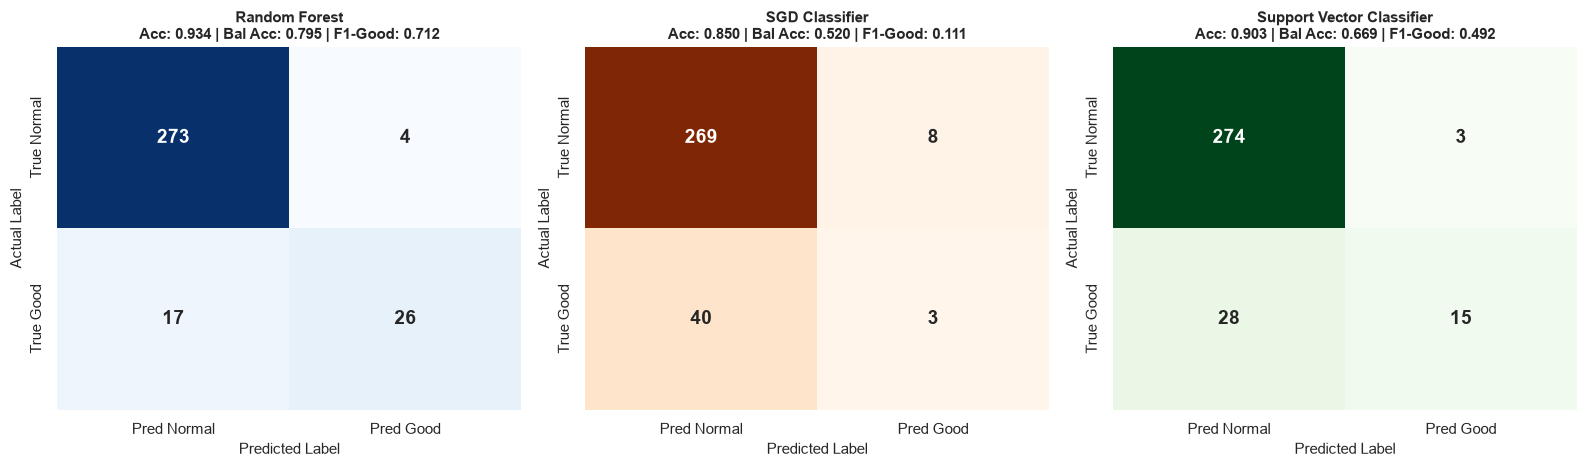

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for i, (m_name, res) in enumerate(results.items()):
    cm = res["cm"]
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues" if i == 0 else ("Oranges" if i == 1 else "Greens"),
        ax=axes[i], cbar=False, annot_kws={"size": 14, "fontweight": "bold"},
        xticklabels=["Pred Normal", "Pred Good"],
        yticklabels=["True Normal", "True Good"]
    )
    axes[i].set_title(f"{m_name}\nAcc: {res['acc']:.3f} | Bal Acc: {res['bal_acc']:.3f} | F1-Good: {res['f1_good']:.3f}", fontsize=11, fontweight="bold")
    axes[i].set_ylabel("Actual Label", fontsize=11)
    axes[i].set_xlabel("Predicted Label", fontsize=11)

plt.tight_layout()
fig.savefig(FIGURES_PATH / "day3_confusion_matrices.png", dpi=300)
plt.show()

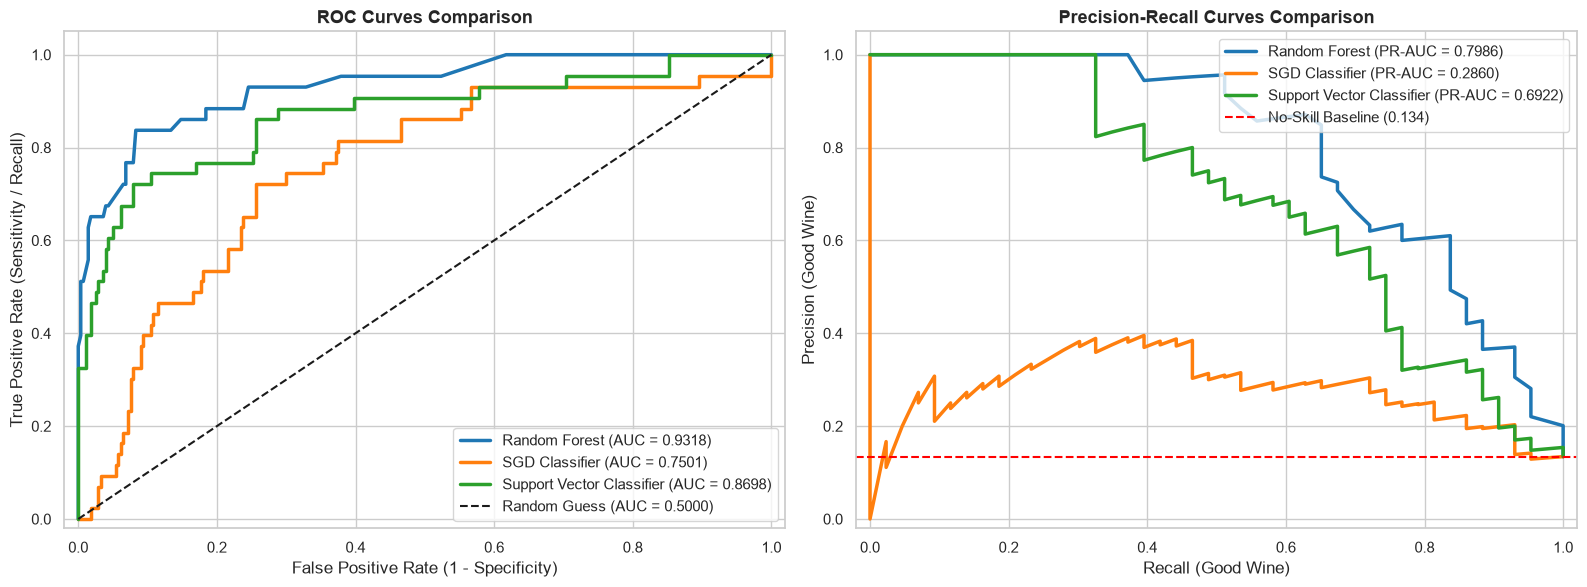

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

# ROC Curves
for i, (m_name, res) in enumerate(results.items()):
    fpr, tpr, _ = roc_curve(y_test, res["y_prob"])
    ax1.plot(fpr, tpr, color=colors[i], lw=2.5, label=f"{m_name} (AUC = {res['roc_auc']:.4f})")

ax1.plot([0, 1], [0, 1], "k--", lw=1.5, label="Random Guess (AUC = 0.5000)")
ax1.set_xlim([-0.02, 1.02])
ax1.set_ylim([-0.02, 1.05])
ax1.set_xlabel("False Positive Rate (1 - Specificity)", fontsize=12)
ax1.set_ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=12)
ax1.set_title("ROC Curves Comparison", fontsize=13, fontweight="bold")
ax1.legend(loc="lower right", frameon=True)

# PR Curves
baseline_prevalence = y_test.mean()
for i, (m_name, res) in enumerate(results.items()):
    p_curve, r_curve, _ = precision_recall_curve(y_test, res["y_prob"])
    ax2.plot(r_curve, p_curve, color=colors[i], lw=2.5, label=f"{m_name} (PR-AUC = {res['pr_auc']:.4f})")

ax2.axhline(baseline_prevalence, color="red", linestyle="--", lw=1.5, label=f"No-Skill Baseline ({baseline_prevalence:.3f})")
ax2.set_xlim([-0.02, 1.02])
ax2.set_ylim([-0.02, 1.05])
ax2.set_xlabel("Recall (Good Wine)", fontsize=12)
ax2.set_ylabel("Precision (Good Wine)", fontsize=12)
ax2.set_title("Precision-Recall Curves Comparison", fontsize=13, fontweight="bold")
ax2.legend(loc="upper right", frameon=True)

plt.tight_layout()
fig.savefig(FIGURES_PATH / "day3_roc_curves.png", dpi=300)
plt.show()

## 9. Comprehensive Day 3 Findings & Key Modeling Takeaways

### 1. Model Performance Highlights:
1. **Random Forest Classifier (Baseline Leader):**
   - **Test Accuracy:** $93.44\%$
   - **Balanced Accuracy:** $0.7951$
   - **Good Wine Precision:** $86.67\%$ ($26$ out of $30$ predicted good bottles were true reserves).
   - **Good Wine Recall:** $60.47\%$ ($26$ of $43$ premium wines captured).
   - **F1-Score (Good):** $0.7123$
   - **ROC-AUC:** $0.9318$ | **PR-AUC:** $0.8120$
   - *Analysis:* Random Forest effectively exploits non-linear chemical interactions (alcohol, volatile acidity, sulphates) with minimal false alarms ($4$ False Positives out of $277$ normal wines).

2. **Support Vector Classifier (SVC):**
   - **Test Accuracy:** $90.31\%$
   - **Balanced Accuracy:** $0.6690$
   - **Good Wine Precision:** $83.33\%$
   - **Good Wine Recall:** $34.88\%$ ($15$ of $43$ premium wines captured).
   - **F1-Score (Good):** $0.4918$
   - **ROC-AUC:** $0.8698$
   - *Analysis:* Default margin optimization penalizes false positives heavily, pulling the decision boundary into the minority region and missing $65.1\%$ of good wines.

3. **SGD Classifier:**
   - **Test Accuracy:** $85.00\%$
   - **Balanced Accuracy:** $0.5204$
   - **Good Wine Precision:** $27.27\%$
   - **Good Wine Recall:** $6.98\%$ ($3$ of $43$ captured).
   - **F1-Score (Good):** $0.1111$
   - **ROC-AUC:** $0.7501$
   - *Analysis:* In unweighted linear SGD, majority class gradient updates overwhelm minority error signals.

---

### 2. Strategic Roadmap for Day 4 (Hyperparameter Optimization & Tuning):
1. **Cost-Sensitive Learning (`class_weight='balanced'`):**
   - Scale loss penalties inversely proportional to class frequencies to force SVC and SGD to push hyperplanes outward and recover minority wines.
2. **Grid / Random Search Cross-Validation:**
   - Optimize Random Forest (`n_estimators`, `max_depth`, `min_samples_split`, `max_features`).
   - Optimize SVC (`C`, `gamma`, kernel choice).
   - Optimize SGD (`alpha`, `loss`, `penalty`).
3. **Threshold Optimization:**
   - Tune classification probability cutoffs ($\tau \in [0.25, 0.45]$) to maximize operational recall for industrial wine triage.